# **Day 87: Matplotlib - Subplots and Showing Satellite Images**

## **Subplots: Many Charts in One Figure**
`plt.subplots(rows, cols)` makes a **figure** (the whole page) with many **axes** (the individual charts). This is the recommended way to use Matplotlib.

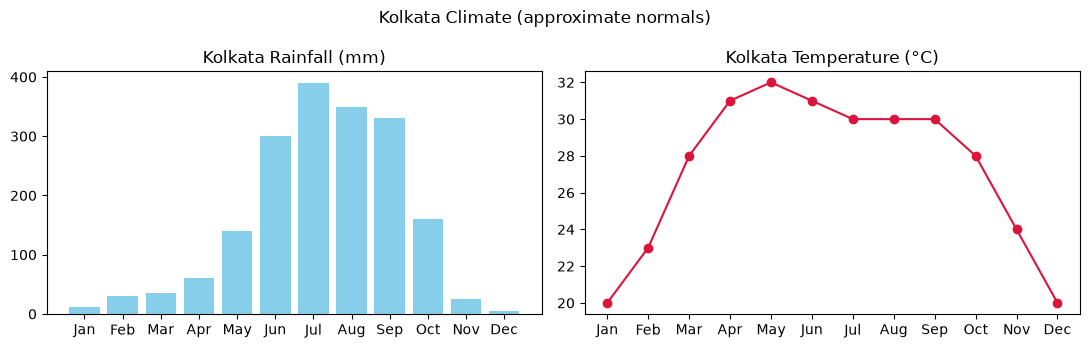

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
rain = [11, 30, 35, 60, 140, 300, 390, 350, 330, 160, 25, 5]
temp = [20, 23, 28, 31, 32, 31, 30, 30, 30, 28, 24, 20]

axes[0].bar(months, rain, color="skyblue")
axes[0].set_title("Kolkata Rainfall (mm)")

axes[1].plot(months, temp, color="crimson", marker="o")
axes[1].set_title("Kolkata Temperature (°C)")

fig.suptitle("Kolkata Climate (approximate normals)")
fig.tight_layout()
plt.show()

With subplots we use **ax** methods: `ax.set_title()`, `ax.set_xlabel()` and so on, instead of `plt.title()`.

## **Making a Synthetic Satellite Image**
To practise, we make a **synthetic** (computer-made) 4-band image of a small coastal area: a winding river, mangrove forest, farm fields, a village and a pond.

In [2]:
rng = np.random.default_rng(7)
rows, cols = 120, 160
y, x = np.mgrid[0:rows, 0:cols]

# Land cover map: 1 water, 2 mangrove, 3 agriculture, 4 built-up
lc = np.full((rows, cols), 3)
river_centre = 35 + 12 * np.sin(y / 15)                 # A winding river
lc[np.abs(x - river_centre) < 8] = 1
lc[(np.abs(x - river_centre) >= 8) & (np.abs(x - river_centre) < 30)] = 2
lc[(x > 105) & (x < 145) & (y > 70) & (y < 105)] = 4      # Village
lc[(x - 125) ** 2 + (y - 30) ** 2 < 120] = 1              # Round pond

# Reflectance (blue, green, red, nir) for each class
sig = {1: (0.07, 0.06, 0.04, 0.02), 2: (0.03, 0.06, 0.03, 0.36),
       3: (0.05, 0.09, 0.07, 0.30), 4: (0.12, 0.13, 0.15, 0.20)}
bands = np.zeros((4, rows, cols))
for c, values in sig.items():
    for b in range(4):
        bands[b][lc == c] = values[b]
bands += rng.normal(0, 0.008, bands.shape)
# Make the farm fields look like separate plots with different crop health
plot_effect = ((x // 20 + y // 20) % 3) * 0.05
bands[3][lc == 3] += plot_effect[lc == 3]
bands = bands.clip(0.001, 1)

blue, green, red, nir = bands
print("Image shape (bands, rows, cols):", bands.shape)

Image shape (bands, rows, cols): (4, 120, 160)


## **Showing One Band with imshow()**
`imshow()` draws a 2D array as an image. Each value becomes a colour using a **colour map** (cmap).

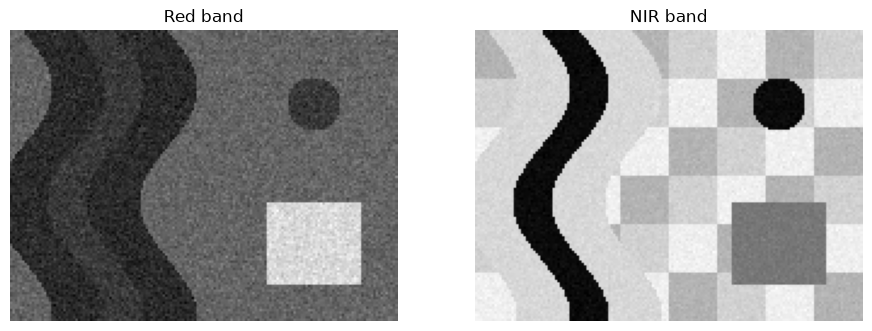

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].imshow(red, cmap="gray")
axes[0].set_title("Red band")

axes[1].imshow(nir, cmap="gray")
axes[1].set_title("NIR band")

for ax in axes:
    ax.axis("off")
plt.show()

- In the **Red band**, vegetation looks **dark** (plants absorb red light).
- In the **NIR band**, vegetation looks **bright** and water looks **black**.

## **True Colour and False Colour Composites**
A **composite** puts three bands into the **Red, Green and Blue** channels of the screen.

- **True colour (Red-Green-Blue):** Looks like a normal photo.
- **False colour (NIR-Red-Green):** NIR is shown as red, so **healthy vegetation looks bright red**. This is the most famous view in Remote Sensing, because it makes vegetation very easy to see.

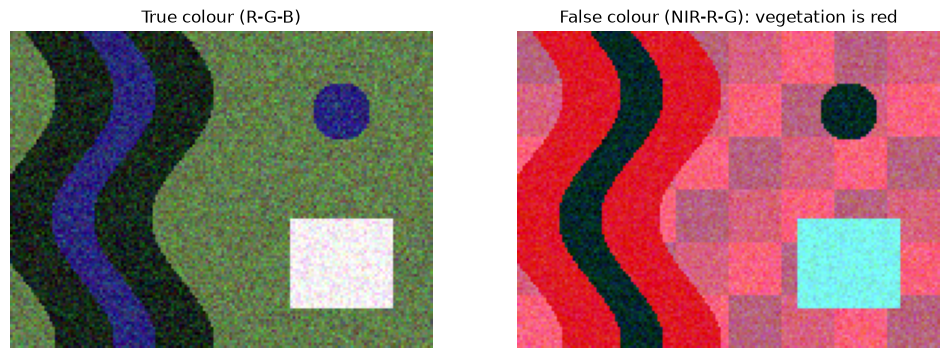

In [4]:
def stretch(band, low=2, high=98):
    """Stretch a band to 0-1 using percentiles, so the image is not too dark."""
    lo, hi = np.percentile(band, [low, high])
    return np.clip((band - lo) / (hi - lo), 0, 1)

true_colour = np.dstack([stretch(red), stretch(green), stretch(blue)])
false_colour = np.dstack([stretch(nir), stretch(red), stretch(green)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(true_colour)
axes[0].set_title("True colour (R-G-B)")
axes[1].imshow(false_colour)
axes[1].set_title("False colour (NIR-R-G): vegetation is red")
for ax in axes:
    ax.axis("off")
plt.show()

Let us understand the code above:
- `np.dstack()` puts the three 2D bands on top of each other to make a (rows, cols, 3) array, which `imshow` shows as a colour image.
- `stretch()` is needed because reflectance values are small (like 0.05). Without stretching, the image would look almost black. This is called **contrast stretching**.

## **NDVI Map with a Colour Bar**
A colour map like **RdYlGn** (Red-Yellow-Green) is perfect for NDVI: red for low values, green for high values.

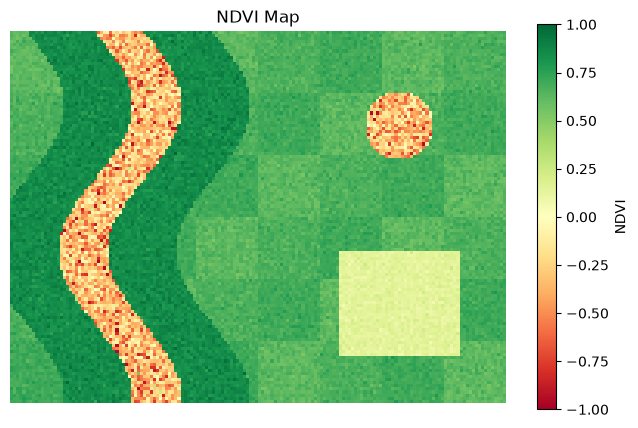

In [5]:
ndvi = (nir - red) / (nir + red)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="NDVI")
ax.set_title("NDVI Map")
ax.axis("off")
plt.show()

## **Classified Map with a Legend**
For a **classified** map, each class gets its own fixed colour. We use a `ListedColormap` and make a legend by hand.

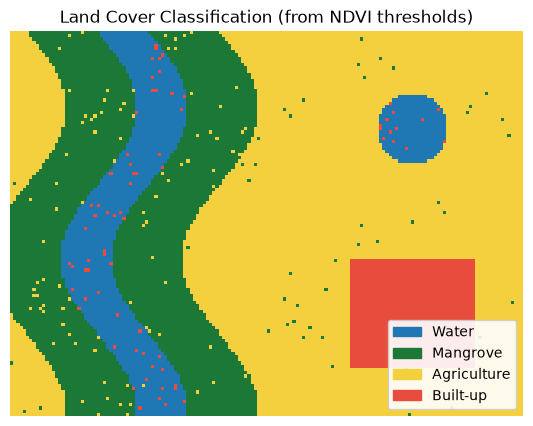

Water        11.6%
Mangrove     26.6%
Agriculture  54.6%
Built-up      7.3%


In [6]:
classified = np.select([ndvi < 0, ndvi < 0.35, ndvi < 0.77], [1, 4, 3], default=2)

colours = ["#1f78b4", "#1b7837", "#f4d03f", "#e74c3c"]       # water, mangrove, agriculture, built-up
names = ["Water", "Mangrove", "Agriculture", "Built-up"]
cmap = ListedColormap(colours)

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(classified, cmap=cmap, vmin=1, vmax=4)
ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(colours, names)],
          loc="lower right", framealpha=0.9)
ax.set_title("Land Cover Classification (from NDVI thresholds)")
ax.axis("off")
plt.show()

for code, name in enumerate(names, start=1):
    share = (classified == code).mean()
    print(f"{name:<12}{share:6.1%}")

## **A Full Figure with Four Panels**

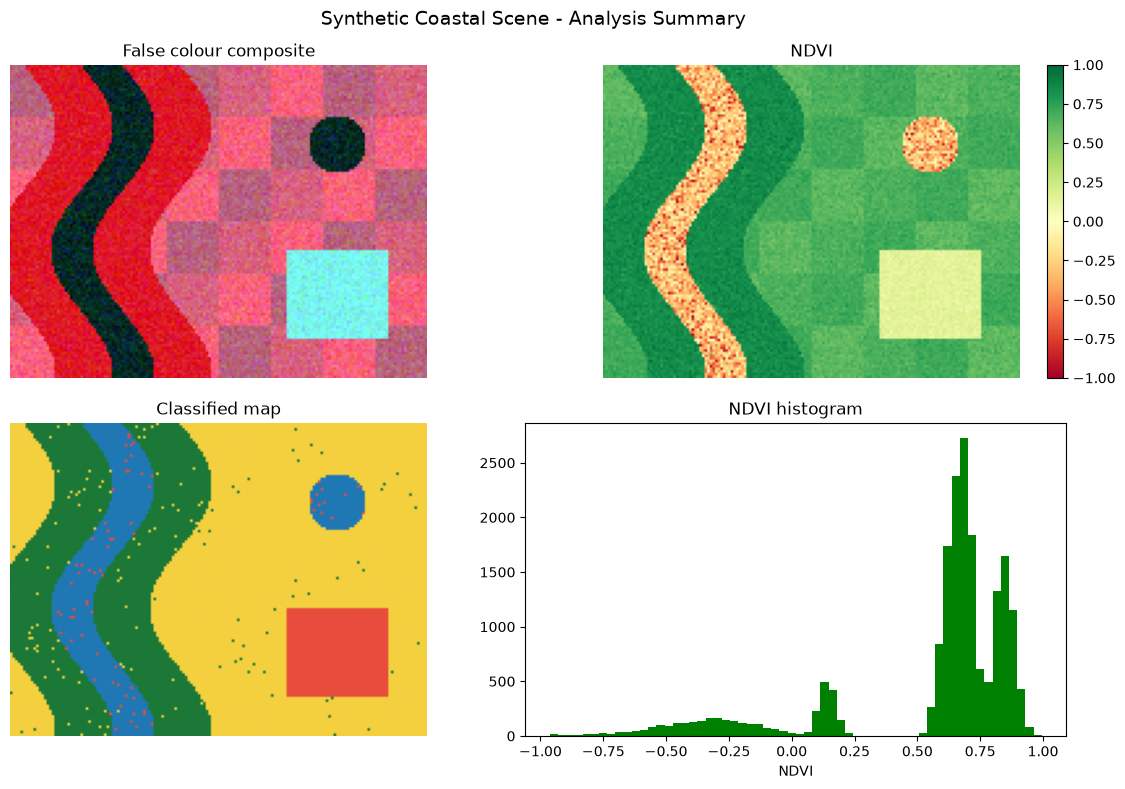

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(false_colour)
axes[0, 0].set_title("False colour composite")

im = axes[0, 1].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0, 1], fraction=0.035)
axes[0, 1].set_title("NDVI")

axes[1, 0].imshow(classified, cmap=cmap, vmin=1, vmax=4)
axes[1, 0].set_title("Classified map")

axes[1, 1].hist(ndvi.ravel(), bins=60, color="green")
axes[1, 1].set_title("NDVI histogram")
axes[1, 1].set_xlabel("NDVI")

for ax in axes.ravel()[:3]:
    ax.axis("off")
fig.suptitle("Synthetic Coastal Scene - Analysis Summary", fontsize=14)
fig.tight_layout()
plt.show()

In [8]:
# Quick question
# In a false colour (NIR-R-G) image, what colour does healthy vegetation look?